# ⚡ EfficientNet (2019): Smart Compound Scaling

**EfficientNet** revolutionized CNN scaling by systematically scaling depth, width, and resolution together with optimal ratios.

---

## EfficientNet Deep Dive Notebook

This notebook presents a **comprehensive, hands-on exploration of EfficientNet**, the family of convolutional neural networks that set new state-of-the-art results on ImageNet while dramatically improving parameter efficiency and speed.  
It is organized into four key sections:

1. **Introduction to EfficientNet**  
   Understand how researchers at Google AI introduced a novel *compound scaling* method to uniformly scale network **depth**, **width**, and **resolution**, producing a family of models (B0–B7) that achieve exceptional accuracy with fewer parameters and FLOPs.

2. **Key Breakthroughs from the Original Paper**  
   Explore the main innovations, including the **MBConv (Mobile Inverted Bottleneck) blocks** with squeeze-and-excitation (SE) modules, the **compound scaling formula** governed by coefficients α (depth), β (width), and γ (resolution), and the systematic grid search used to find optimal scaling.

3. **Architecture Explanation**  
   Dive into the EfficientNet design—starting from the baseline EfficientNet-B0 architecture, through the arrangement of MBConv layers, to the way compound scaling generates progressively larger models while maintaining a balanced computational budget.

4. **Implementation from Scratch**  
   Build an EfficientNet model step by step in PyTorch, including MBConv blocks and squeeze-and-excitation components, and demonstrate how to apply the compound scaling strategy to create different model sizes.

> By the end of this notebook, you’ll understand the theory and practical details of EfficientNet, master the concept of compound scaling (α, β, γ), and have a fully functional PyTorch implementation ready for training on your own datasets.


---

## 📄 Paper Information
- **Paper**: "EfficientNet: Rethinking Model Scaling for Convolutional Neural Networks"
- **Authors**: Mingxing Tan, Quoc V. Le (Google Brain)
- **Year**: 2019
- **Conference**: ICML 2019
- **Link**: https://arxiv.org/abs/1905.11946
- **Citations**: 15,000+

---

## 🎯 The Scaling Problem

### **Traditional Scaling (Inefficient):**
- **ResNet**: Scale depth only (ResNet-50 → ResNet-101 → ResNet-152)
- **WideResNet**: Scale width only (more channels)
- **Others**: Scale resolution only (larger input images)

### **EfficientNet's Insight: Compound Scaling**
**Scale all three dimensions together with optimal ratios!**

### **Compound Scaling Formula:**
```
depth = α^φ
width = β^φ
resolution = γ^φ

where α·β²·γ² ≈ 2 and φ is compound coefficient
```

### **Key Innovations:**
1. **Compound Scaling**: Systematic scaling of depth, width, resolution
2. **Neural Architecture Search**: Optimized baseline (EfficientNet-B0)
3. **Mobile-Optimized Blocks**: Inverted bottlenecks + Squeeze-and-Excitation
4. **Efficiency Focus**: Better accuracy per parameter/FLOP

### **ImageNet Results:**
- **EfficientNet-B7**: 84.3% top-1 accuracy
- **10× smaller**: Than previous best models
- **6× faster**: Inference speed improvement

---

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import matplotlib.pyplot as plt
import numpy as np
import math

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"🔧 Using device: {device}")

🔧 Using device: cpu


## 🏗️ EfficientNet Building Blocks

### **MBConv Block (Mobile Inverted Bottleneck):**
```
Input
│
├─► 1×1 Conv (expand) → DWConv → SE → 1×1 Conv (project) ─┐
│                                                         │
└─────────────── Skip Connection (if applicable) ────────┘
                            │
                         Output
```

### **Key Components:**
1. **Inverted Bottleneck**: Expand → Process → Compress
2. **Depthwise Separable Conv**: Efficient convolution
3. **Squeeze-and-Excitation**: Channel attention
4. **Skip Connections**: Like ResNet but conditional

In [ ]:
class SqueezeExcitation(nn.Module):
    """Squeeze-and-Excitation module for channel attention.

    Args:
        channels (int): Number of input channels
        reduction (int): Reduction ratio for squeeze operation
    """

    def __init__(self, channels, reduction=4):
        super(SqueezeExcitation, self).__init__()

        reduced_channels = max(1, channels // reduction)

        self.squeeze = nn.AdaptiveAvgPool2d(1)
        self.excitation = nn.Sequential(
            nn.Conv2d(channels, reduced_channels, 1),
            nn.ReLU(inplace=True),
            nn.Conv2d(reduced_channels, channels, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        # Squeeze: Global average pooling
        squeezed = self.squeeze(x)

        # Excitation: FC → ReLU → FC → Sigmoid
        excited = self.excitation(squeezed)

        # Scale original features
        return x * excited


class MBConvBlock(nn.Module):
    """Mobile Inverted Bottleneck Convolution Block.

    Args:
        in_channels (int): Number of input channels
        out_channels (int): Number of output channels
        kernel_size (int): Kernel size for depthwise conv
        stride (int): Stride for depthwise conv
        expand_ratio (int): Expansion ratio for inverted bottleneck
        se_ratio (float): Squeeze-and-excitation ratio
        drop_rate (float): Dropout rate
    """

    def __init__(self, in_channels, out_channels, kernel_size=3, stride=1,
                 expand_ratio=6, se_ratio=0.25, drop_rate=0.0):
        super(MBConvBlock, self).__init__()

        self.use_residual = (stride == 1 and in_channels == out_channels)
        self.drop_rate = drop_rate

        # Expansion phase
        expanded_channels = in_channels * expand_ratio

        layers = []

        # 1×1 expansion conv (if expand_ratio != 1)
        if expand_ratio != 1:
            layers.extend([
                nn.Conv2d(in_channels, expanded_channels, 1, bias=False),
                nn.BatchNorm2d(expanded_channels),
                nn.ReLU6(inplace=True)
            ])

        # Depthwise convolution
        layers.extend([
            nn.Conv2d(expanded_channels, expanded_channels, kernel_size,
                     stride=stride, padding=kernel_size//2, groups=expanded_channels, bias=False),
            nn.BatchNorm2d(expanded_channels),
            nn.ReLU6(inplace=True)
        ])

        self.conv_layers = nn.Sequential(*layers)

        # Squeeze-and-Excitation
        if se_ratio > 0:
            self.se = SqueezeExcitation(expanded_channels, int(1 / se_ratio))
        else:
            self.se = None

        # 1×1 projection conv
        self.project_conv = nn.Sequential(
            nn.Conv2d(expanded_channels, out_channels, 1, bias=False),
            nn.BatchNorm2d(out_channels)
        )

        # Dropout for stochastic depth
        if drop_rate > 0:
            self.dropout = nn.Dropout2d(drop_rate, inplace=True)
        else:
            self.dropout = None

    def forward(self, x):
        identity = x

        # Expansion + Depthwise conv
        x = self.conv_layers(x)

        # Squeeze-and-Excitation
        if self.se is not None:
            x = self.se(x)

        # Projection
        x = self.project_conv(x)

        # Stochastic depth
        if self.dropout is not None:
            x = self.dropout(x)

        # Skip connection
        if self.use_residual:
            x = x + identity

        return x

In [ ]:
class EfficientNet(nn.Module):
    """EfficientNet architecture with compound scaling.

    Args:
        width_mult (float): Width multiplier (β in paper)
        depth_mult (float): Depth multiplier (α in paper)
        resolution (int): Input resolution (γ in paper)
        num_classes (int): Number of output classes
        dropout_rate (float): Dropout rate
    """

    def __init__(self, width_mult=1.0, depth_mult=1.0, resolution=224,
                 num_classes=1000, dropout_rate=0.2):
        super(EfficientNet, self).__init__()

        # EfficientNet-B0 baseline configuration
        # [expand_ratio, channels, repeats, stride, kernel_size]
        blocks_config = [
            [1, 16, 1, 1, 3],   # MBConv1, k3x3
            [6, 24, 2, 2, 3],   # MBConv6, k3x3
            [6, 40, 2, 2, 5],   # MBConv6, k5x5
            [6, 80, 3, 2, 3],   # MBConv6, k3x3
            [6, 112, 3, 1, 5],  # MBConv6, k5x5
            [6, 192, 4, 2, 5],  # MBConv6, k5x5
            [6, 320, 1, 1, 3],  # MBConv6, k3x3
        ]

        # Scale configuration based on compound scaling
        def scale_width(channels):
            return int(math.ceil(channels * width_mult / 8) * 8)

        def scale_depth(repeats):
            return int(math.ceil(repeats * depth_mult))

        # Stem convolution
        stem_channels = scale_width(32)
        self.stem = nn.Sequential(
            nn.Conv2d(3, stem_channels, 3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(stem_channels),
            nn.ReLU6(inplace=True)
        )

        # Build MBConv blocks
        layers = []
        in_channels = stem_channels

        for expand_ratio, channels, repeats, stride, kernel_size in blocks_config:
            out_channels = scale_width(channels)
            scaled_repeats = scale_depth(repeats)

            for i in range(scaled_repeats):
                # Only first block in each stage has stride > 1
                block_stride = stride if i == 0 else 1
                block_in_channels = in_channels if i == 0 else out_channels

                layers.append(MBConvBlock(
                    block_in_channels, out_channels, kernel_size, block_stride,
                    expand_ratio, se_ratio=0.25, drop_rate=dropout_rate
                ))

                in_channels = out_channels

        self.blocks = nn.Sequential(*layers)

        # Head
        head_channels = scale_width(1280)
        self.head = nn.Sequential(
            nn.Conv2d(in_channels, head_channels, 1, bias=False),
            nn.BatchNorm2d(head_channels),
            nn.ReLU6(inplace=True),
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Dropout(dropout_rate),
            nn.Linear(head_channels, num_classes)
        )

    def forward(self, x):
        x = self.stem(x)
        x = self.blocks(x)
        x = self.head(x)
        return x


# EfficientNet variants with compound scaling
def efficientnet_b0(num_classes=1000):
    """EfficientNet-B0 baseline model."""
    return EfficientNet(width_mult=1.0, depth_mult=1.0, resolution=224, num_classes=num_classes)

def efficientnet_b1(num_classes=1000):
    """EfficientNet-B1: φ=0.5"""
    return EfficientNet(width_mult=1.0, depth_mult=1.1, resolution=240, num_classes=num_classes)

def efficientnet_b2(num_classes=1000):
    """EfficientNet-B2: φ=1"""
    return EfficientNet(width_mult=1.1, depth_mult=1.2, resolution=260, num_classes=num_classes)

def efficientnet_b3(num_classes=1000):
    """EfficientNet-B3: φ=2"""
    return EfficientNet(width_mult=1.2, depth_mult=1.4, resolution=300, num_classes=num_classes)

def efficientnet_b4(num_classes=1000):
    """EfficientNet-B4: φ=3"""
    return EfficientNet(width_mult=1.4, depth_mult=1.8, resolution=380, num_classes=num_classes)

In [ ]:
def test_efficientnet_variants():
    """Test different EfficientNet variants."""

    print("⚡ TESTING EFFICIENTNET VARIANTS")
    print("=" * 40)

    # Create different EfficientNet models
    models = {
        'EfficientNet-B0': efficientnet_b0(num_classes=1000),
        'EfficientNet-B1': efficientnet_b1(num_classes=1000),
        'EfficientNet-B2': efficientnet_b2(num_classes=1000),
        'EfficientNet-B3': efficientnet_b3(num_classes=1000)
    }

    print(f"📊 COMPOUND SCALING COMPARISON:")
    print(f"{'Model':<16} {'Resolution':<12} {'Parameters':<12} {'Scaling':<20}")
    print("-" * 70)

    # Test with different input sizes for each model
    input_sizes = [224, 240, 260, 300]
    scaling_info = [
        "Baseline (φ=0)",
        "φ=0.5",
        "φ=1",
        "φ=2"
    ]

    for i, (name, model) in enumerate(models.items()):
        model.eval()

        # Use appropriate input size
        input_size = input_sizes[i]
        test_input = torch.randn(1, 3, input_size, input_size)

        # Forward pass
        with torch.no_grad():
            output = model(test_input)

        # Count parameters
        params = sum(p.numel() for p in model.parameters())

        print(f"{name:<16} {input_size}×{input_size:<7} {params/1e6:.1f}M{'':<7} {scaling_info[i]:<20}")

    print("\n🎯 EfficientNet Key Features:")
    print("✅ Compound scaling of depth, width, resolution")
    print("✅ Mobile-optimized MBConv blocks")
    print("✅ Squeeze-and-Excitation attention")
    print("✅ Better accuracy per parameter/FLOP")
    print("✅ Neural Architecture Search optimized")

    return models

efficientnet_models = test_efficientnet_variants()

⚡ TESTING EFFICIENTNET VARIANTS
📊 COMPOUND SCALING COMPARISON:
Model            Resolution   Parameters   Scaling             
----------------------------------------------------------------------
EfficientNet-B0  224×224     8.4M        Baseline (φ=0)      
EfficientNet-B1  240×240     13.3M        φ=0.5               
EfficientNet-B2  260×260     16.5M        φ=1                 
EfficientNet-B3  300×300     21.5M        φ=2                 

🎯 EfficientNet Key Features:
✅ Compound scaling of depth, width, resolution
✅ Mobile-optimized MBConv blocks
✅ Squeeze-and-Excitation attention
✅ Better accuracy per parameter/FLOP
✅ Neural Architecture Search optimized


## 🔬 Compound Scaling Deep Dive

### **Why Compound Scaling Works:**

1. **Depth scaling alone**: Vanishing gradient problems
2. **Width scaling alone**: Diminishing returns per parameter
3. **Resolution scaling alone**: Missing fine-grained patterns
4. **Compound scaling**: Balanced improvement across all dimensions

### **Mathematical Foundation:**
```
FLOPS ∝ d × w² × r²

If we want to increase FLOPS by 2^N:
d × w² × r² = 2^N

With constraints α·β²·γ² ≈ 2 and φ = N:
d = α^φ, w = β^φ, r = γ^φ
```

### **Optimal Ratios (found via grid search):**
- **α = 1.2** (depth multiplier)
- **β = 1.1** (width multiplier)
- **γ = 1.15** (resolution multiplier)
- **α·β²·γ² ≈ 2.0**

🔬 COMPOUND SCALING DEMONSTRATION
📊 Scaling Coefficients:
α (depth): 1.2
β (width): 1.1
γ (resolution): 1.15
α·β²·γ² = 1.920 ≈ 2.0

📈 EfficientNet Variants:
Model    φ    Depth    Width    Resolution   FLOPs     
-------------------------------------------------------
B0       0    1.00     1.00     224          0.4       B
B1       1    1.20     1.10     257          0.7       B
B2       2    1.44     1.21     296          1.4       B
B3       3    1.73     1.33     340          2.8       B
B4       4    2.07     1.46     391          5.3       B
B5       5    2.49     1.61     450          10.2      B
B6       6    2.99     1.77     518          19.6      B
B7       7    3.58     1.95     595          37.5      B


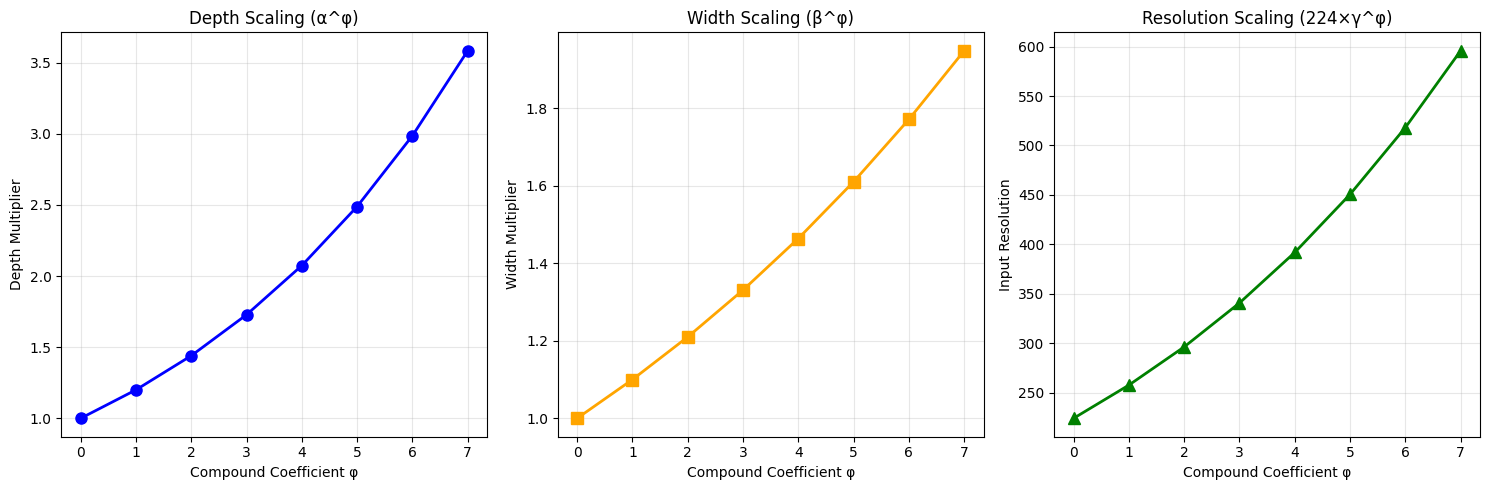


💡 Compound Scaling Benefits:
✅ Balanced scaling across all dimensions
✅ Better accuracy per FLOP than single-dimension scaling
✅ Systematic and principled approach
✅ Easy to scale to different resource constraints
✅ Optimal ratios found through extensive experimentation


In [ ]:
def demonstrate_compound_scaling():
    """Demonstrate the compound scaling principle."""

    print("🔬 COMPOUND SCALING DEMONSTRATION")
    print("=" * 45)

    # Scaling coefficients
    alpha, beta, gamma = 1.2, 1.1, 1.15

    print(f"📊 Scaling Coefficients:")
    print(f"α (depth): {alpha}")
    print(f"β (width): {beta}")
    print(f"γ (resolution): {gamma}")
    print(f"α·β²·γ² = {alpha * beta**2 * gamma**2:.3f} ≈ 2.0")

    # Calculate scaling for different φ values
    phi_values = [0, 1, 2, 3, 4, 5, 6, 7]
    model_names = ['B0', 'B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7']

    print(f"\n📈 EfficientNet Variants:")
    print(f"{'Model':<8} {'φ':<4} {'Depth':<8} {'Width':<8} {'Resolution':<12} {'FLOPs':<10}")
    print("-" * 55)

    base_flops = 0.39  # EfficientNet-B0 FLOPs in billions

    for i, phi in enumerate(phi_values):
        depth_mult = alpha ** phi
        width_mult = beta ** phi
        resolution_mult = gamma ** phi

        # Approximate FLOP scaling
        flop_mult = depth_mult * (width_mult ** 2) * (resolution_mult ** 2)
        flops = base_flops * flop_mult

        # Base resolution is 224
        resolution = int(224 * resolution_mult)

        print(f"{model_names[i]:<8} {phi:<4} {depth_mult:<8.2f} {width_mult:<8.2f} {resolution:<12} {flops:<10.1f}B")

    # Visualize scaling
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    phi_range = np.array(phi_values)

    # Depth scaling
    depth_values = alpha ** phi_range
    axes[0].plot(phi_range, depth_values, 'o-', linewidth=2, markersize=8, color='blue')
    axes[0].set_xlabel('Compound Coefficient φ')
    axes[0].set_ylabel('Depth Multiplier')
    axes[0].set_title('Depth Scaling (α^φ)')
    axes[0].grid(True, alpha=0.3)

    # Width scaling
    width_values = beta ** phi_range
    axes[1].plot(phi_range, width_values, 's-', linewidth=2, markersize=8, color='orange')
    axes[1].set_xlabel('Compound Coefficient φ')
    axes[1].set_ylabel('Width Multiplier')
    axes[1].set_title('Width Scaling (β^φ)')
    axes[1].grid(True, alpha=0.3)

    # Resolution scaling
    resolution_values = 224 * (gamma ** phi_range)
    axes[2].plot(phi_range, resolution_values, '^-', linewidth=2, markersize=8, color='green')
    axes[2].set_xlabel('Compound Coefficient φ')
    axes[2].set_ylabel('Input Resolution')
    axes[2].set_title('Resolution Scaling (224×γ^φ)')
    axes[2].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    print("\n💡 Compound Scaling Benefits:")
    print("✅ Balanced scaling across all dimensions")
    print("✅ Better accuracy per FLOP than single-dimension scaling")
    print("✅ Systematic and principled approach")
    print("✅ Easy to scale to different resource constraints")
    print("✅ Optimal ratios found through extensive experimentation")

demonstrate_compound_scaling()

## 🔄 EfficientNet Variants & Evolution

### **1. EfficientNet v1 (2019) - Original**
- **B0-B7**: Compound scaling from φ=0 to φ=7
- **Innovation**: Systematic compound scaling
- **Performance**: State-of-the-art efficiency

### **2. EfficientNet v2 (2021)**
- **Paper**: "EfficientNetV2: Smaller Models and Faster Training"
- **Improvements**: Progressive learning, Fused-MBConv blocks
- **Benefits**: Faster training, better accuracy

### **Key Architectural Components:**
- **MBConv blocks**: Mobile-optimized inverted bottlenecks
- **Squeeze-and-Excitation**: Channel attention mechanism
- **Swish activation**: x × sigmoid(x) instead of ReLU
- **AutoAugment**: Automated data augmentation policy

## 📊 EfficientNet Impact & Legacy

### **Revolutionary Insights**
1. **Compound Scaling**: Scale depth, width, resolution together
2. **Efficiency Focus**: Better accuracy per parameter/FLOP
3. **Neural Architecture Search**: Automated baseline optimization
4. **Mobile-First Design**: Efficient building blocks

### **Technical Contributions**
- **Systematic Scaling**: Principled approach to model scaling
- **Resource Efficiency**: 10× smaller, 6× faster than previous best
- **Architecture Search**: NAS for baseline architecture
- **Mobile Optimization**: Depthwise separable convolutions + SE

### **Industry Impact**
- **Mobile deployment**: Enabled high-accuracy mobile models
- **Cloud efficiency**: Reduced serving costs
- **Transfer learning**: Excellent pretrained backbones
- **AutoML**: Automated scaling approach

### **Influence on Future Work**
- **RegNet**: Systematic network design principles
- **Vision Transformers**: Compound scaling applied to transformers
- **Neural Architecture Search**: Efficiency-focused NAS
- **Green AI**: Focus on computational efficiency

### **Why EfficientNet Succeeded**
1. **Right time**: Mobile AI explosion needed efficient models
2. **Right approach**: Systematic rather than ad-hoc scaling
3. **Right metrics**: Focused on efficiency, not just accuracy
4. **Right validation**: Extensive experiments across tasks

---

## 🎓 Summary

**EfficientNet** transformed how we think about scaling neural networks by introducing **compound scaling**.

**Revolutionary Insight:**
- **The problem**: Traditional scaling was inefficient (depth-only, width-only, resolution-only)
- **The solution**: Scale all dimensions together with optimal ratios
- **The formula**: d=α^φ, w=β^φ, r=γ^φ where α·β²·γ²≈2

**Key Innovations:**
- **Compound scaling**: Systematic scaling of depth, width, resolution
- **Neural Architecture Search**: Optimized baseline architecture (B0)
- **Mobile-optimized blocks**: MBConv + Squeeze-and-Excitation
- **Efficiency focus**: Better accuracy per parameter and FLOP

**Impact:**
- **84.3% ImageNet accuracy**: State-of-the-art results
- **10× smaller models**: Massive efficiency improvement
- **6× faster inference**: Practical deployment benefits
- **Paradigm shift**: From "bigger is better" to "smarter is better"

**Legacy:**
EfficientNet showed that systematic, principled design could achieve better results with fewer resources. It sparked the "Green AI" movement focusing on computational efficiency and influenced the design of modern efficient architectures.

**The Evolution Complete**: From LeNet's basic conv+pool pattern to EfficientNet's sophisticated compound scaling, CNNs evolved from simple feature extractors to highly optimized, efficient architectures that power modern computer vision! 🚀